 01 — Modèles de base entraînés de zéro (Partie 1)

Objectifs (énoncé, Partie 1.2 à 1.6) :
- **CNN-Plain** : 6 couches Conv–BN–ReLU, pooling, tête dense avec Dropout ; dimensions calculées à la main puis vérifiées avec `torchinfo` ;
- **CNN-Res** : même profondeur, blocs résiduels et Global Average Pooling, à budget de paramètres comparable ;
- **étude du learning rate** sur 3 valeurs ;
- **norme du gradient par couche** (hooks) pour les deux modèles ;
- **tableau comparatif** : paramètres, taille, temps, accuracy, F1 macro.

Résolution : **128×128** (conseil de l'énoncé pour les CNN entraînés de zéro).

**Protocole :** l'étude du learning rate se juge sur la **validation** ; seuls les deux modèles finaux (CNN-Plain et CNN-Res, entraînés avec le LR retenu) sont évalués **une fois** sur le test.

In [1]:
# === Configuration (Colab, Kaggle ou local) ===
ALLOW_CPU = False   # True seulement pour les notebooks sans entraînement (00 et 06)
REPO_URL = "https://github.com/fayelise/diagnoculture.git"   # utilisé sur Kaggle uniquement

import os, sys, subprocess
from pathlib import Path

# 1. Environnement. Colab est testé AVANT Kaggle : sur Colab, kagglehub peut créer /kaggle/input.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
IN_KAGGLE = not IN_COLAB and "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB:
    # Projet sur Google Drive : résultats et checkpoints survivent aux déconnexions
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/diagnoculture")
    os.environ["DIAGNO_CACHE"] = "/content/cache"   # cache d'images sur le disque local de Colab (rapide)
    for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):   # jeton Kaggle (Secrets Colab)
        try:
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
elif IN_KAGGLE:
    # Code cloné depuis GitHub ; résultats du notebook précédent (ajouté en Input) recopiés
    # dans /kaggle/working : l'Output de ce notebook contiendra donc toute la chaîne.
    import shutil
    ROOT = Path("/kaggle/working/diagnoculture")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    for inp in Path("/kaggle/input").iterdir():
        for prev in (inp / "results", inp / "diagnoculture" / "results"):
            if (prev / "00_split").is_dir():
                shutil.copytree(prev, ROOT / "results", dirs_exist_ok=True)
else:
    # Local : notebook lancé depuis notebooks/ ou depuis la racine du dépôt
    ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

assert (ROOT / "src" / "utils.py").exists(), f"Projet introuvable dans {ROOT} (voir README, section Installation)"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# 2. Paquets absents des images Colab / Kaggle (en local : pip install -r requirements.txt)
if IN_COLAB or IN_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo==1.8.0", "ImageHash==4.3.2",
                    "grad-cam==1.5.7", "onnx==1.23.2", "onnxruntime==1.29.0",
                    "umap-learn==0.5.12", "kagglehub==1.0.2"], check=True)

# 3. Configuration du projet
from src.utils import load_config, resolve_paths, set_seed, ensure_data, get_device, machine_info, TestGuard
cfg = load_config()
set_seed(cfg["seed"])
paths = resolve_paths(cfg)
DATA_ROOT = ensure_data(cfg)          # télécharge PlantVillage au 1er lancement de la session (hors Kaggle)
DEVICE = get_device()
guard = TestGuard(paths["results"])   # le test ne sert qu'une fois par modèle final
FORCE_TEST_RERUN = False              # True uniquement pour ré-exécuter à l'identique après une coupure
print("Projet :", ROOT, "| données :", DATA_ROOT, "| device :", DEVICE)
print(machine_info())

# 4. Garde-fou GPU : sur CPU, chaque epoch est 40 à 80 fois plus lente et le budget train.max_minutes
#    coupe les entraînements après 1 à 4 epochs (cause des résultats invalides de la 1re exécution).
#    DIAGNO_ALLOW_CPU=1 sert uniquement au test rapide du pipeline (README).
if DEVICE.type != "cuda" and not (ALLOW_CPU or os.environ.get("DIAGNO_ALLOW_CPU") == "1"):
    raise RuntimeError("Pas de GPU : Exécution → Modifier le type d'exécution → T4 GPU "
                       "(Kaggle : Session options → Accelerator → GPU T4).")

Mounted at /content/drive
Téléchargement de abdallahalidev/plantvillage-dataset via kagglehub (~2 Go, quelques minutes)...
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Données téléchargées dans : /kaggle/input/plantvillage-dataset
Projet : /content/drive/MyDrive/diagnoculture | données : /kaggle/input/plantvillage-dataset/plantvillage dataset/color | device : cuda
{'env': 'colab', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'cpu': 'x86_64', 'cpu_count': 2, 'gpu': 'Tesla T4'}


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torchinfo import summary

from src.datasets import CLASSES, TensorImageDataset, build_transform, get_split_tensors, make_loader
from src.latency import count_params, model_size_mb
from src.models import CNNPlain, CNNRes, conv_layers
from src.train import GradNormRecorder, final_test_evaluation, fit_classifier, load_best, record_experiment
from src.utils import load_json, save_json

P1 = cfg["part1"]
SIZE = cfg["resolution"]["scratch"]
OUT = paths["results"] / "01_cnn_scratch"
OUT.mkdir(parents=True, exist_ok=True)
norm = load_json(paths["split_dir"] / "norm_stats.json")   # statistiques du TRAIN (notebook 00)

data = get_split_tensors(paths, DATA_ROOT, SIZE)
tf_train = build_transform(True, norm["mean"], norm["std"])
tf_eval = build_transform(False, norm["mean"], norm["std"])
ds = {s: TensorImageDataset(x, df["label"], tf_train if s == "train" else tf_eval) for s, (df, x) in data.items()}
BS, NW = cfg["train"]["batch_size"], cfg["data"]["num_workers"]
new_train_loader = lambda: make_loader(ds["train"], BS, True, NW, cfg["seed"])  # recréé à chaque run : même ordre de mélange
val_loader = make_loader(ds["val"], 256, False, NW)
test_loader = make_loader(ds["test"], 256, False, NW)
print({s: len(d) for s, d in ds.items()})

{'train': 12712, 'val': 2722, 'test': 2726}


| Choix      | Valeur                                                          | Justification (cours Ch. 2)                                                                                                                                                          |
|:-----------|:----------------------------------------------------------------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Noyau F    | 3×3                                                             | deux 3×3 empilées couvrent le même champ réceptif qu'une 5×5 avec moins de paramètres (18C² vs 25C²) et une non-linéarité de plus (idée de VGG)                                     |
| Padding P  | 1 (*same*)                                                      | avec F = 3 et S = 1, la convolution conserve H×W ; la réduction est confiée au pooling, ce qui rend les dimensions faciles à suivre                                                 |
| Pas S      | 1                                                               | aucune information perdue dans la convolution                                                                                                                                        |
| Pooling    | MaxPool 2×2, S = 2 après chaque conv                            | divise H et W par 2 : réduit le coût et agrandit le champ réceptif ; garde la réponse la plus forte (présence d'une lésion)                                                          |
| Filtres K  | 32, 32, 64, 64, 128, 128                                        | on double les canaux quand la résolution diminue : couches basses = motifs simples peu nombreux, couches hautes = motifs complexes plus nombreux                                     |
| BatchNorm  | après chaque conv                                               | stabilise la distribution des activations, autorise un LR plus élevé, léger effet régularisant                                                                                       |
| Tête       | Flatten → Dense 128 → ReLU → Dropout 0,5 → Dense 10             | le Dropout régularise la partie dense, la plus sujette au sur-apprentissage                                                                                                          |


Formule (Ch. 2) : $O = \dfrac{W - F + 2P}{S} + 1$.

- Conv : $O = (W - 3 + 2)/1 + 1 = W$
- MaxPool ($F=2$, $S=2$, $P=0$) : $O = (W - 2)/2 + 1 = W/2$

Paramètres d'une conv sans biais : $F \times F \times C_{in} \times C_{out}$ ; BatchNorm : $2\,C_{out}$ (γ et β apprenables).


| Couche                | Calcul                | Sortie (C × H × W) | Paramètres                |
|:----------------------|:----------------------|:-------------------|--------------------------:|
| Entrée                | —                     | 3 × 128 × 128      | 0                         |
| Conv1 3×3, 32 + BN    | (128−3+2)/1+1 = 128   | 32 × 128 × 128     | 3·3·3·32 + 64 = 928       |
| MaxPool               | (128−2)/2+1 = 64      | 32 × 64 × 64       | 0                         |
| Conv2 3×3, 32 + BN    | 64                    | 32 × 64 × 64       | 3·3·32·32 + 64 = 9 280    |
| MaxPool               | 32                    | 32 × 32 × 32       | 0                         |
| Conv3 3×3, 64 + BN    | 32                    | 64 × 32 × 32       | 3·3·32·64 + 128 = 18 560  |
| MaxPool               | 16                    | 64 × 16 × 16       | 0                         |
| Conv4 3×3, 64 + BN    | 16                    | 64 × 16 × 16       | 3·3·64·64 + 128 = 36 992  |
| MaxPool               | 8                     | 64 × 8 × 8         | 0                         |
| Conv5 3×3, 128 + BN   | 8                     | 128 × 8 × 8        | 3·3·64·128 + 256 = 73 984 |
| MaxPool               | 4                     | 128 × 4 × 4        | 0                         |
| Conv6 3×3, 128 + BN   | 4                     | 128 × 4 × 4        | 3·3·128·128 + 256 = 147 712 |
| MaxPool               | 2                     | 128 × 2 × 2        | 0                         |
| Flatten               | 128·2·2               | 512                | 0                         |
| Dense + ReLU          | 512 → 128             | 128                | 512·128 + 128 = 65 664    |
| Dropout 0,5           | —                     | 128                | 0                         |
| Dense                 | 128 → 10              | 10                 | 128·10 + 10 = 1 290       |
| **Total**             |                       |                    | **354 410**               |

In [3]:
plain = CNNPlain(len(CLASSES), P1["channels"], dropout=P1["dropout"])
print(summary(plain, input_size=(1, 3, SIZE, SIZE), col_names=("output_size", "num_params", "mult_adds"), verbose=0))
assert count_params(plain) == 354_410, "Le total ne correspond pas au calcul manuel"

Layer (type:depth-idx)                   Output Shape              Param #                   Mult-Adds
CNNPlain                                 [1, 10]                   --                        --
├─Sequential: 1-1                        [1, 128, 2, 2]            --                        --
│    └─Sequential: 2-1                   [1, 32, 128, 128]         --                        --
│    │    └─Conv2d: 3-1                  [1, 32, 128, 128]         864                       14,155,776
│    │    └─BatchNorm2d: 3-2             [1, 32, 128, 128]         64                        64
│    │    └─ReLU: 3-3                    [1, 32, 128, 128]         --                        --
│    └─MaxPool2d: 2-2                    [1, 32, 64, 64]           --                        --
│    └─Sequential: 2-3                   [1, 32, 64, 64]           --                        --
│    │    └─Conv2d: 3-4                  [1, 32, 64, 64]           9,216                     37,748,736
│    │    └─Batch

## 2. CNN-Res : même profondeur, connexions résiduelles, GAP

3 `ResidualBlock` × 2 convolutions 3×3 = **6 couches convolutives** sur le chemin principal (comme CNN-Plain). Le raccourci est l'identité, ou une **convolution 1×1** quand le nombre de canaux change (projection : $C_{in}·C_{out}$ paramètres, aucune information spatiale mélangée).

| Bloc                   | Sortie                             | Paramètres                               |
|:-----------------------|:-----------------------------------|-----------------------------------------:|
| RB 3→32 (2 conv + 1×1) | 32 × 128 × 128 → pool 32 × 64 × 64 | 864 + 9 216 + 96 + 3 BN (192) = 10 368   |
| RB 32→64               | 64 × 64 × 64 → pool 64 × 32 × 32   | 18 432 + 36 864 + 2 048 + 384 = 57 728   |
| RB 64→128              | 128 × 32 × 32 → pool 128 × 16 × 16 | 73 728 + 147 456 + 8 192 + 768 = 230 144 |
| GAP                    | 128 × 16 × 16 → 128                | 0                                        |
| Dropout + Dense        | 128 → 10                           | 1 290                                    |
| **Total**              |                                    | **299 530**                              |

**Budget comparable** : 0,30 M contre 0,35 M paramètres (−15 %). Le **GAP** remplace Flatten + Dense (65 664 paramètres économisés) : moyenne de chaque carte → un nombre par canal, sans paramètre, avec une invariance à la position de la lésion.

À paramètres comparables, CNN-Res fait **plus de calculs** (ses convolutions travaillent sur des cartes plus grandes, voir la colonne *mult-adds*) : budget de paramètres ≠ budget de calcul.

In [4]:
res = CNNRes(len(CLASSES), P1["res_channels"], dropout=P1["dropout"])
print(summary(res, input_size=(1, 3, SIZE, SIZE), col_names=("output_size", "num_params", "mult_adds"), verbose=0))
assert count_params(res) == 299_530
print(f"Couches conv 3x3 : Plain = {len(conv_layers(plain))}, Res = {len(conv_layers(res))}")

Layer (type:depth-idx)                   Output Shape              Param #                   Mult-Adds
CNNRes                                   [1, 10]                   --                        --
├─Sequential: 1-1                        [1, 128, 16, 16]          --                        --
│    └─ResidualBlock: 2-1                [1, 32, 128, 128]         --                        --
│    │    └─Conv2d: 3-1                  [1, 32, 128, 128]         864                       14,155,776
│    │    └─BatchNorm2d: 3-2             [1, 32, 128, 128]         64                        64
│    │    └─ReLU: 3-3                    [1, 32, 128, 128]         --                        --
│    │    └─Conv2d: 3-4                  [1, 32, 128, 128]         9,216                     150,994,944
│    │    └─BatchNorm2d: 3-5             [1, 32, 128, 128]         64                        64
│    │    └─Sequential: 3-6              [1, 32, 128, 128]         160                       1,572,928
│    │   

3. Étude du learning rate (3 valeurs)

Le learning rate est l'hyperparamètre le plus influent (Ch. 1) : trop grand → la perte oscille ou diverge ; trop petit → convergence lente, sous-apprentissage dans le budget d'epochs. On compare $10^{-2}$, $10^{-3}$, $10^{-4}$ (optimiseur AdamW, décroissance *cosine*) sur CNN-Plain, `lr_study_epochs` epochs chacun. **Choix sur le F1 macro de validation**, pas sur le test.

Reprise depuis l'epoch 8 (temps déjà écoulé : 3.1 min)
[lr_study_0.001] epoch  1/8 | loss 1.083/0.551 | acc 0.628/0.805 | F1 val 0.730 | 25s
[lr_study_0.001] epoch  2/8 | loss 0.585/0.445 | acc 0.805/0.829 | F1 val 0.758 | 23s
[lr_study_0.001] epoch  3/8 | loss 0.429/0.466 | acc 0.859/0.841 | F1 val 0.788 | 24s
[lr_study_0.001] epoch  4/8 | loss 0.324/0.242 | acc 0.897/0.914 | F1 val 0.882 | 23s
[lr_study_0.001] epoch  5/8 | loss 0.254/0.147 | acc 0.920/0.952 | F1 val 0.935 | 23s
[lr_study_0.001] epoch  6/8 | loss 0.209/0.127 | acc 0.933/0.957 | F1 val 0.940 | 23s
[lr_study_0.001] epoch  7/8 | loss 0.172/0.115 | acc 0.944/0.962 | F1 val 0.946 | 23s
[lr_study_0.001] epoch  8/8 | loss 0.143/0.093 | acc 0.954/0.969 | F1 val 0.956 | 23s
[lr_study_0.0001] epoch  1/8 | loss 1.421/0.809 | acc 0.538/0.747 | F1 val 0.574 | 22s
[lr_study_0.0001] epoch  2/8 | loss 0.784/0.522 | acc 0.745/0.838 | F1 val 0.769 | 22s
[lr_study_0.0001] epoch  3/8 | loss 0.588/0.391 | acc 0.809/0.880 | F1 val 0.832 | 

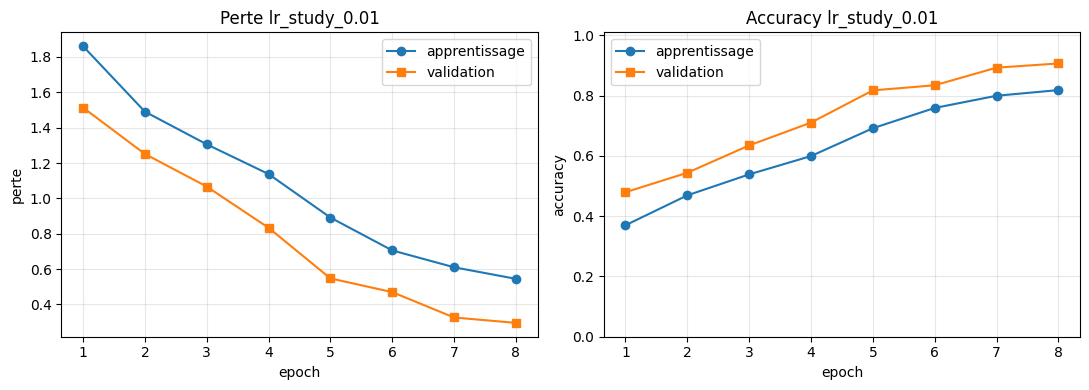

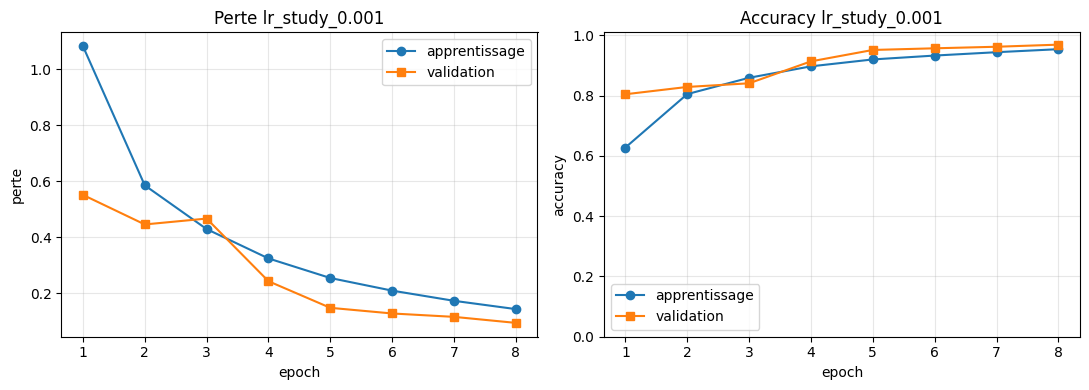

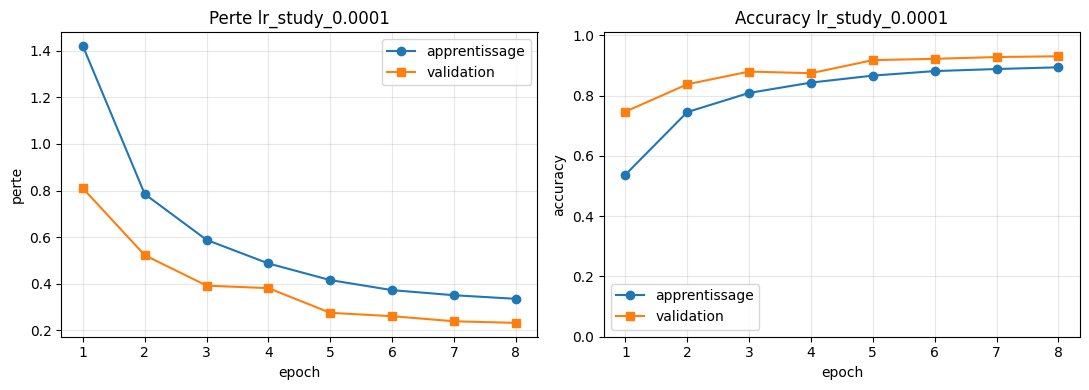

In [5]:
lr_hist = {}
for lr in P1["lr_study"]:
    set_seed(cfg["seed"])   # même initialisation pour les 3 runs : seule la valeur du LR change
    m = CNNPlain(len(CLASSES), P1["channels"], dropout=P1["dropout"])
    hp = {"model": "CNNPlain", "lr": lr, "epochs": P1["lr_study_epochs"], "batch_size": BS,
          "weight_decay": P1["weight_decay"], "dropout": P1["dropout"], "img_size": SIZE, "optimizer": "AdamW+cosine"}
    exp = OUT / f"lr_study_{lr:g}"
    lr_hist[lr] = fit_classifier(m, new_train_loader(), val_loader, exp, P1["lr_study_epochs"],
                                 [{"params": m.parameters(), "lr": lr}], P1["weight_decay"],
                                 cfg["train"]["amp"], cfg["train"]["max_minutes"], cfg["train"]["resume"], hparams=hp)
    record_experiment(paths["results"], f"P1_lr_study_{lr:g}", "1", m, exp, SIZE, hparams=hp,
                      notes="étude du LR (validation uniquement, pas de test)")

F1 macro de validation max : {0.01: 0.8692, 0.001: 0.9562, 0.0001: 0.906}
Learning rate retenu (sur la VALIDATION) : 0.001


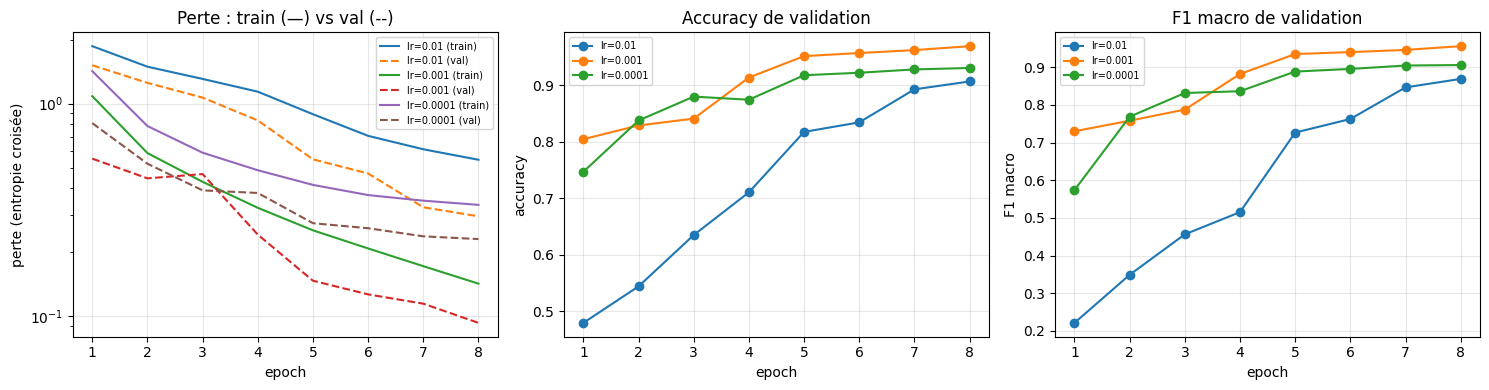

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for lr, h in lr_hist.items():
    axes[0].plot(h["epoch"], h["train_loss"], "-", label=f"lr={lr:g} (train)")
    axes[0].plot(h["epoch"], h["val_loss"], "--", label=f"lr={lr:g} (val)")
    axes[1].plot(h["epoch"], h["val_acc"], "o-", label=f"lr={lr:g}")
    axes[2].plot(h["epoch"], h["val_f1"], "o-", label=f"lr={lr:g}")
axes[0].set(xlabel="epoch", ylabel="perte (entropie croisée)", title="Perte : train (—) vs val (--)", yscale="log")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy de validation")
axes[2].set(xlabel="epoch", ylabel="F1 macro", title="F1 macro de validation")
for a in axes:
    a.grid(alpha=0.3)
    a.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "lr_study.png", dpi=150)

best_lr = max(lr_hist, key=lambda lr: lr_hist[lr]["val_f1"].max())
print("F1 macro de validation max :", {lr: round(float(h["val_f1"].max()), 4) for lr, h in lr_hist.items()})
print(f"Learning rate retenu (sur la VALIDATION) : {best_lr:g}")
save_json({"best_lr": best_lr}, OUT / "lr_choice.json")

Le learning rate retenu (sur la validation) est réutilisé pour CNN-Plain et CNN-Res finaux.

## 4. Entraînement final + norme du gradient par couche

Pendant l'entraînement, un **hook** est attaché au poids de chaque convolution 3×3 (`weight.register_hook`) : à chaque rétropropagation, autograd appelle le hook avec $\partial L / \partial W$ ; on enregistre sa norme toutes les `grad_log_every` itérations.

**Ce qu'on cherche** : dans un réseau sans raccourci, le gradient d'une couche basse est un produit de nombreuses jacobiennes ; s'il diminue de couche en couche vers l'entrée, c'est le *vanishing gradient*. Avec une connexion résiduelle, $y = F(x) + x \Rightarrow \partial y/\partial x = \partial F/\partial x + I$ : le terme identité fournit un chemin direct au gradient.

[cnn-plain] epoch  1/15 | loss 1.083/0.551 | acc 0.628/0.805 | F1 val 0.730 | 23s
[cnn-plain] epoch  2/15 | loss 0.581/0.367 | acc 0.805/0.862 | F1 val 0.810 | 22s
[cnn-plain] epoch  3/15 | loss 0.446/0.384 | acc 0.852/0.867 | F1 val 0.826 | 22s
[cnn-plain] epoch  4/15 | loss 0.354/0.310 | acc 0.886/0.895 | F1 val 0.857 | 23s
[cnn-plain] epoch  5/15 | loss 0.285/0.195 | acc 0.908/0.935 | F1 val 0.911 | 23s
[cnn-plain] epoch  6/15 | loss 0.254/0.236 | acc 0.916/0.914 | F1 val 0.888 | 22s
[cnn-plain] epoch  7/15 | loss 0.221/0.178 | acc 0.927/0.942 | F1 val 0.917 | 22s
[cnn-plain] epoch  8/15 | loss 0.178/0.100 | acc 0.942/0.968 | F1 val 0.956 | 22s
[cnn-plain] epoch  9/15 | loss 0.172/0.110 | acc 0.943/0.963 | F1 val 0.948 | 22s
[cnn-plain] epoch 10/15 | loss 0.139/0.107 | acc 0.954/0.963 | F1 val 0.950 | 22s
[cnn-plain] epoch 11/15 | loss 0.119/0.094 | acc 0.962/0.971 | F1 val 0.961 | 22s
[cnn-plain] epoch 12/15 | loss 0.098/0.074 | acc 0.969/0.976 | F1 val 0.968 | 22s
[cnn-plain] epoc

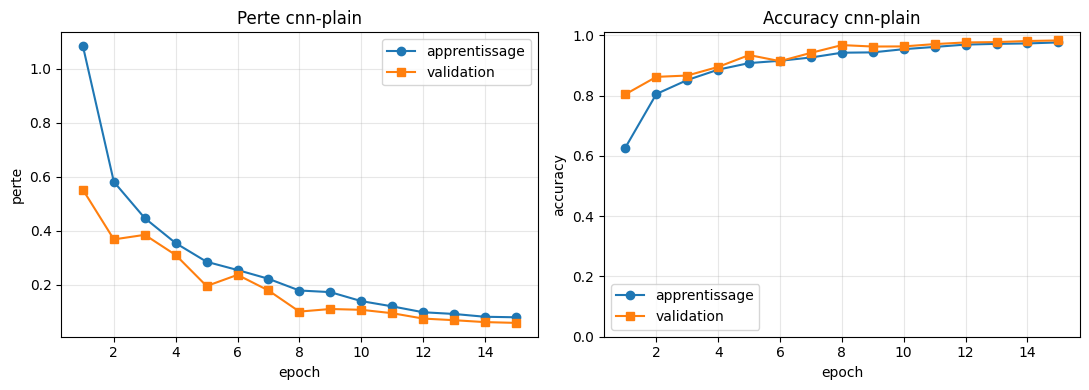

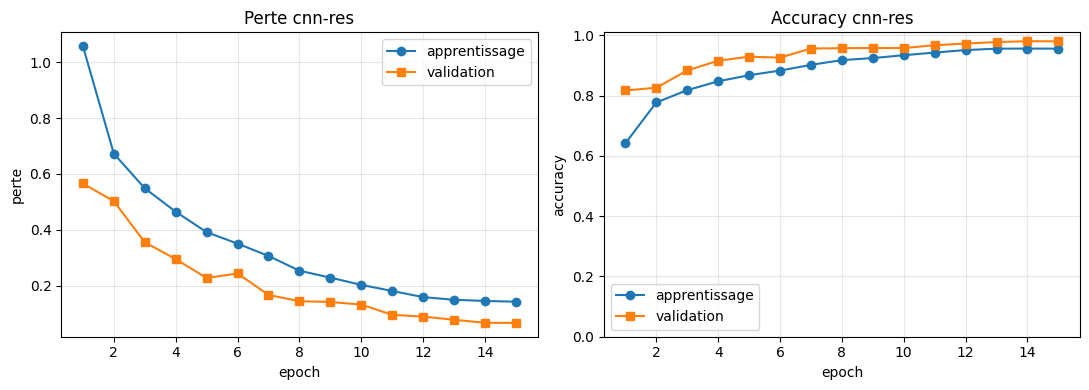

In [7]:
final = {}
for name, ctor in [("CNN-Plain", lambda: CNNPlain(len(CLASSES), P1["channels"], dropout=P1["dropout"])),
                   ("CNN-Res", lambda: CNNRes(len(CLASSES), P1["res_channels"], dropout=P1["dropout"]))]:
    set_seed(cfg["seed"])
    m = ctor()
    rec = GradNormRecorder(conv_layers(m), every=P1["grad_log_every"])
    hp = {"model": name, "lr": best_lr, "epochs": P1["epochs"], "batch_size": BS, "weight_decay": P1["weight_decay"],
          "dropout": P1["dropout"], "img_size": SIZE, "optimizer": "AdamW+cosine", "augment": "flips, rot15, jitter"}
    exp = OUT / name.lower()
    hist = fit_classifier(m, new_train_loader(), val_loader, exp, P1["epochs"], [{"params": m.parameters(), "lr": best_lr}],
                          P1["weight_decay"], cfg["train"]["amp"], cfg["train"]["max_minutes"],
                          cfg["train"]["resume"], grad_recorder=rec, hparams=hp)
    rec.remove()
    g = rec.to_frame()
    if len(g):  # (vide si l'entraînement était déjà terminé et a été repris)
        g.to_csv(exp / "grad_norms.csv", index=False)
    final[name] = {"model": m, "exp": exp, "hist": hist, "hp": hp}

CNN-Plain : ratio gradient conv1 / conv6 = 0.19
CNN-Res : ratio gradient conv1 / conv6 = 0.14


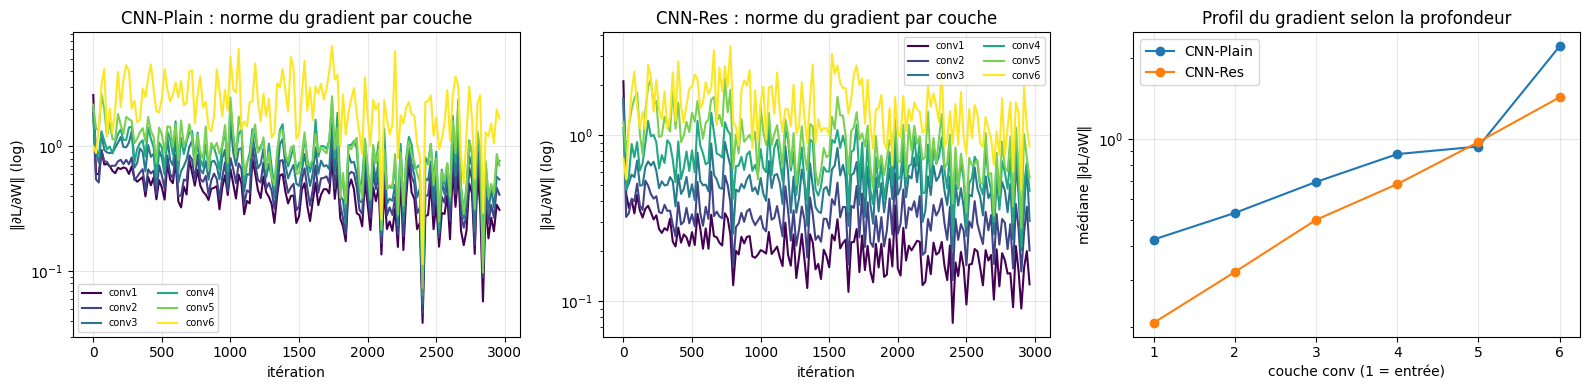

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
summary_g = {}
for k, (name, f) in enumerate(final.items()):
    g = pd.read_csv(f["exp"] / "grad_norms.csv")
    order = list(dict.fromkeys(g["layer"]))
    for i, layer in enumerate(order):
        s = g[g["layer"] == layer]
        axes[k].plot(s["step"], s["grad_norm"], color=plt.cm.viridis(i / (len(order) - 1)), label=f"conv{i + 1}")
    axes[k].set(yscale="log", xlabel="itération", ylabel="‖∂L/∂W‖ (log)", title=f"{name} : norme du gradient par couche")
    axes[k].legend(fontsize=7, ncol=2)
    summary_g[name] = g.groupby("layer", sort=False)["grad_norm"].median().to_numpy()
x = np.arange(1, 7)
for name, v in summary_g.items():
    axes[2].plot(x, v, "o-", label=name)
axes[2].set(yscale="log", xlabel="couche conv (1 = entrée)", ylabel="médiane ‖∂L/∂W‖",
            title="Profil du gradient selon la profondeur")
axes[2].legend()
for a in axes:
    a.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "grad_norms.png", dpi=150)
for name, v in summary_g.items():
    print(f"{name} : ratio gradient conv1 / conv6 = {v[0] / v[-1]:.2f}")

## 5. Évaluation finale sur le test (une seule fois par modèle)

On recharge les poids du **meilleur epoch selon la validation** (`best.pt`), puis évaluation unique sur le test, enregistrée par le `TestGuard`.

CNN-Plain — rappel par classe : {'Bacterial_spot': 0.972, 'Early_blight': 0.96, 'Late_blight': 0.969, 'Leaf_Mold': 0.986, 'Septoria_leaf_spot': 0.974, 'Spider_mites': 0.976, 'Target_Spot': 0.981, 'Yellow_Leaf_Curl_Virus': 0.995, 'Tomato_mosaic_virus': 0.982, 'healthy': 1.0}
CNN-Res — rappel par classe : {'Bacterial_spot': 0.95, 'Early_blight': 0.96, 'Late_blight': 0.948, 'Leaf_Mold': 0.986, 'Septoria_leaf_spot': 0.985, 'Spider_mites': 0.996, 'Target_Spot': 0.976, 'Yellow_Leaf_Curl_Virus': 1.0, 'Tomato_mosaic_virus': 0.982, 'healthy': 0.996}


,modèle,paramètres,taille (Mo),temps d'entraînement (min),accuracy test,F1 macro test
0,CNN-Plain,354410,1.43,5.6,0.9824,0.9784
1,CNN-Res,299530,1.22,6.3,0.9813,0.9778


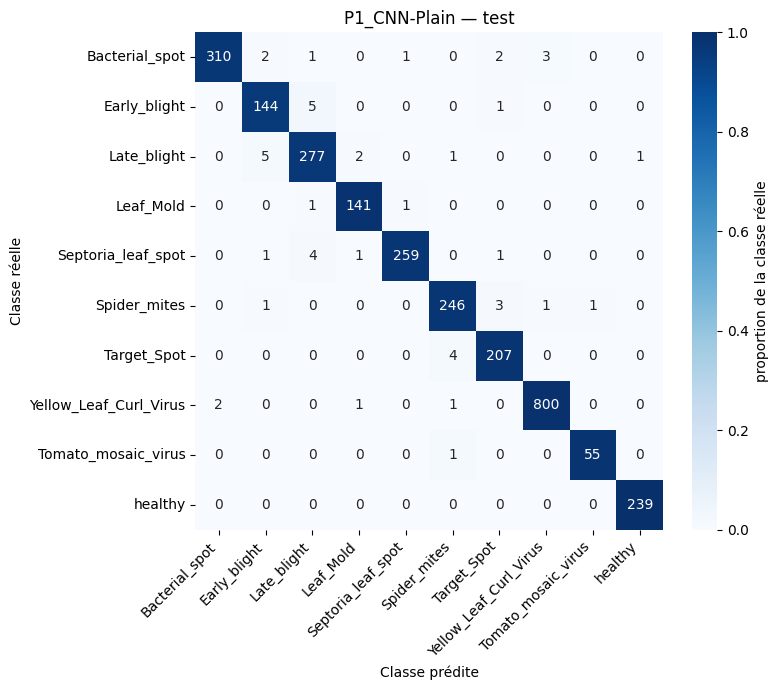

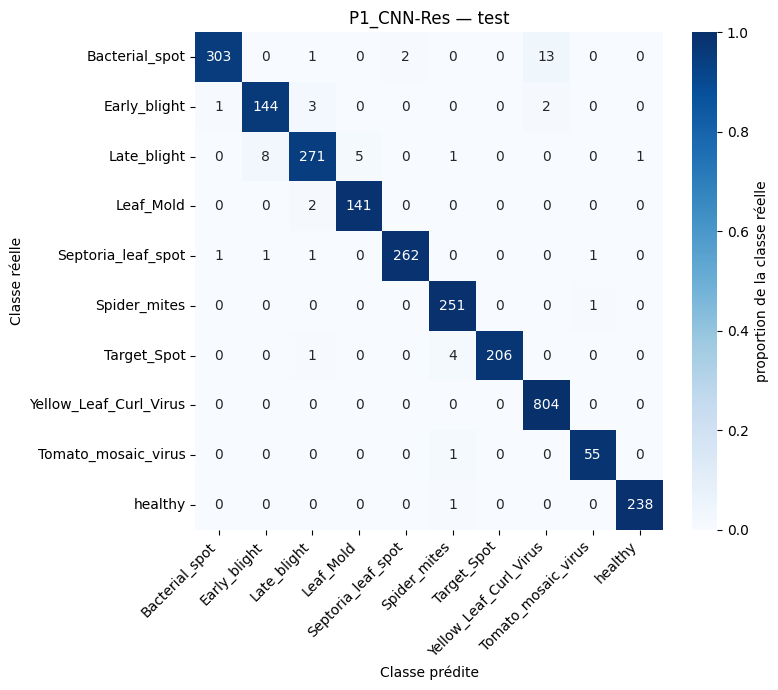

In [9]:
rows = []
for name, f in final.items():
    m = load_best(f["model"], f["exp"])
    tm = final_test_evaluation(m, test_loader, CLASSES, f["exp"], f"P1_{name}", guard, force=FORCE_TEST_RERUN)
    info = load_json(f["exp"] / "train_info.json")
    record_experiment(paths["results"], f"P1_{name}", "1", m, f["exp"], SIZE, tm, f["hp"])
    rows.append({"modèle": name, "paramètres": count_params(m), "taille (Mo)": round(model_size_mb(m), 2),
                 "temps d'entraînement (min)": round(info["train_time_s"] / 60, 1),
                 "accuracy test": round(tm["accuracy"], 4), "F1 macro test": round(tm["f1_macro"], 4)})
    print(name, "— rappel par classe :", {c: round(r, 3) for c, r in tm["recall_per_class"].items()})
comp = pd.DataFrame(rows)
comp.to_csv(OUT / "comparison_table.csv", index=False)
comp

La latence de CNN-Plain et CNN-Res est mesurée dans le notebook 02 (front de Pareto).